# Quantum Light Source Design: Simulations

**Question:** which operating point and herald detector give the most useful single photons from an integrated microring pair source?

**Designs compared:**

| | Design |
|---|---|
| D1 | Attenuated laser, mean 0.1 photons per pulse (baseline) |
| D2 | Heralded ring, μ = 0.01 pairs per pulse, click herald |
| D3 | Heralded ring, μ = 0.1, click herald |
| D4 | Heralded ring, μ = 0.1, photon-number-resolving (PNR) herald |
| D5 | Heralded ring, μ = 0.01, PNR herald |

**Assumed parameters (not measured device data):** 100 MHz pump repetition rate, herald-arm efficiency η_h = 0.5, signal-arm efficiency η_s = 0.5.

The full write-up is in [`design_report.md`](design_report.md). The same model as a plain script is [`analysis.py`](analysis.py).

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

## Model

1. **Pair state.** One signal–idler resonance pair is a two-mode squeezed vacuum with mean μ photons per arm (notebook 08).
2. **Heralding.** A detector on the idler fires with probability $w_k$ for $k$ idler photons: click detector $w_k = 1-(1-\eta_h)^k$, PNR detector (exactly one count) $w_k = k\eta_h(1-\eta_h)^{k-1}$. The heralded signal is the partial trace weighted by $w_k$.
3. **Loss.** The signal passes a beam splitter of transmission η_s with an empty hidden mode, which is traced out (notebook 05).
4. **Figures of merit.** $P(1)$, $P(\ge2)$, heralded $g^{(2)}(0)$, herald rate, delivered single-photon rate.

Analytic checks: herald probability $p_h = \eta_h\mu/(1+\eta_h\mu)$; for small μ, $g^{(2)} \approx 2\mu(2-\eta_h)$ (click) and $\approx 4\mu(1-\eta_h)$ (PNR).

In [2]:
N = 10                       # photon-number cutoff per mode (identical results at 14)
REP = 100e6                  # ASSUMED pump repetition rate
ETA_H = 0.5                  # ASSUMED herald-arm efficiency
ETA_S = 0.5                  # ASSUMED signal-arm efficiency

a, n = qt.destroy(N), qt.num(N)

def pair_state(mu):
    x = mu / (1 + mu)                                    # tanh^2 r
    psi = sum(np.sqrt((1 - x) * x**k) * qt.tensor(qt.basis(N, k), qt.basis(N, k)) for k in range(N))
    return qt.ket2dm(psi)

def herald_weights(eta, kind):
    k = np.arange(N)
    if kind == "click":
        return 1 - (1 - eta) ** k
    return np.where(k > 0, k * eta * (1 - eta) ** np.maximum(k - 1, 0), 0.0)

def herald(mu, eta_h, kind):
    M = qt.tensor(qt.qeye(N), qt.Qobj(np.diag(np.sqrt(herald_weights(eta_h, kind)))))
    unnorm = (M * pair_state(mu) * M).ptrace(0)
    p = unnorm.tr().real
    return unnorm / p, p

A = qt.tensor(qt.destroy(N), qt.qeye(N))
B = qt.tensor(qt.qeye(N), qt.destroy(N))
def lossy(rho, eta):
    th = np.arccos(np.sqrt(eta))
    U = (th * (A.dag() * B - A * B.dag())).expm()
    return (U * qt.tensor(rho, qt.ket2dm(qt.basis(N, 0))) * U.dag()).ptrace(0)

def stats(rho):
    P = rho.diag().real
    g2 = qt.expect(a.dag() * a.dag() * a * a, rho) / qt.expect(n, rho) ** 2
    return P[0], P[1], 1 - P[0] - P[1], g2

def g2_series(mu, eta, kind):
    # exact heralded g2 summed by hand, independent of QuTiP
    x = mu / (1 + mu)
    k = np.arange(200)
    if kind == "click":
        wk = x**k * np.where(k > 0, 1 - (1 - eta) ** k, 0)
    else:
        wk = x**k * k * eta * (1 - eta) ** np.maximum(k - 1, 0)
    return np.sum(k * (k - 1) * wk) * np.sum(wk) / np.sum(k * wk) ** 2

## 1. Validation of the heralding model

In [3]:
for mu in [0.01, 0.1]:
    for kind in ["click", "pnr"]:
        rho, p = herald(mu, ETA_H, kind)
        if kind == "click":
            check(f"herald probability, mu = {mu}", p, ETA_H * mu / (1 + ETA_H * mu))
        check(f"heralded g2, {kind}, mu = {mu}", stats(rho)[3], g2_series(mu, ETA_H, kind))

rho, _ = herald(0.1, ETA_H, "click")
check("g2 unchanged by 50% signal loss", stats(lossy(rho, ETA_S))[3], stats(rho)[3])
print(f"small-mu approximation at mu = 0.1: {2 * 0.1 * (2 - ETA_H):.3f} vs exact {g2_series(0.1, ETA_H, 'click'):.3f}")

PASS  herald probability, mu = 0.01: simulation = 0.0050, theory = 0.0050
PASS  heralded g2, click, mu = 0.01: simulation = 0.0294, theory = 0.0294
PASS  heralded g2, pnr, mu = 0.01: simulation = 0.0197, theory = 0.0197
PASS  herald probability, mu = 0.1: simulation = 0.0476, theory = 0.0476
PASS  heralded g2, click, mu = 0.1: simulation = 0.2500, theory = 0.2500
PASS  heralded g2, pnr, mu = 0.1: simulation = 0.1701, theory = 0.1701
PASS  g2 unchanged by 50% signal loss: simulation = 0.2500, theory = 0.2500
small-mu approximation at mu = 0.1: 0.300 vs exact 0.250


## 2. Design comparison

In [4]:
rows = []
laser = lossy(qt.coherent_dm(N, np.sqrt(0.1)), ETA_S)
_, P1, P2, g2 = stats(laser)
rows.append(("D1 attenuated laser, mu=0.1", None, P1, P2, g2, P1 * REP / 1e6))

for name, mu, kind in [("D2 ring, mu=0.01, click", 0.01, "click"),
                       ("D3 ring, mu=0.1, click", 0.1, "click"),
                       ("D4 ring, mu=0.1, PNR", 0.1, "pnr"),
                       ("D5 ring, mu=0.01, PNR", 0.01, "pnr")]:
    rho, p = herald(mu, ETA_H, kind)
    _, P1, P2, g2 = stats(lossy(rho, ETA_S))
    rows.append((name, p * REP / 1e6, P1, P2, g2, p * P1 * REP / 1e6))

print(f"{'design':<30}{'herald MHz':>11}{'P(1)':>8}{'P(>=2)':>9}{'g2(0)':>8}{'single photons MHz':>20}")
for name, hr, P1, P2, g2, sp in rows:
    hr_s = "  none" if hr is None else f"{hr:.2f}"
    print(f"{name:<30}{hr_s:>11}{P1:>8.3f}{P2:>9.4f}{g2:>8.3f}{sp:>20.2f}")

design                         herald MHz    P(1)   P(>=2)   g2(0)  single photons MHz
D1 attenuated laser, mu=0.1          none   0.048   0.0012   1.000                4.76
D2 ring, mu=0.01, click              0.50   0.500   0.0037   0.029                0.25
D3 ring, mu=0.1, click               4.76   0.498   0.0368   0.250                2.37
D4 ring, mu=0.1, PNR                 4.54   0.499   0.0238   0.170                2.26
D5 ring, mu=0.01, PNR                0.50   0.500   0.0025   0.020                0.25


The laser's single photons arrive in pulses that are 95 % empty and never announced, so a circuit cannot time them. Among the heralded designs, the PNR herald lowers $g^{(2)}(0)$ by about a third for under 5 % of the rate. **D5 has the lowest multi-photon noise.**

## 3. Rate vs purity: the pump dial

mu = 0.001  herald rate  0.050 MHz   g2 click 0.0030   g2 PNR 0.0020
mu = 0.003  herald rate  0.150 MHz   g2 click 0.0089   g2 PNR 0.0060
mu = 0.01   herald rate  0.498 MHz   g2 click 0.0294   g2 PNR 0.0197
mu = 0.03   herald rate  1.478 MHz   g2 click 0.0849   g2 PNR 0.0570
mu = 0.1    herald rate  4.762 MHz   g2 click 0.2500   g2 PNR 0.1701


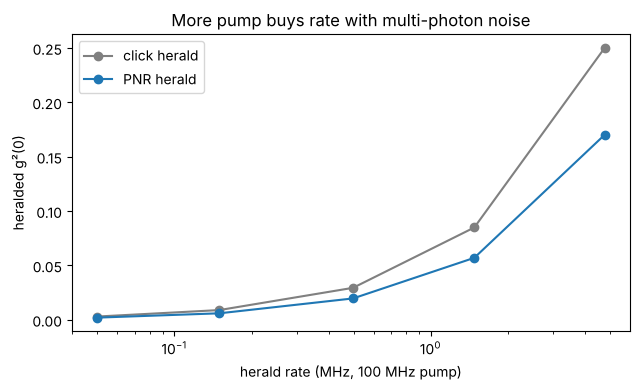

In [5]:
import matplotlib.pyplot as plt
mus = np.array([0.001, 0.003, 0.01, 0.03, 0.1])
rate = [herald(m, ETA_H, "click")[1] * REP / 1e6 for m in mus]
g_click = [stats(herald(m, ETA_H, "click")[0])[3] for m in mus]
g_pnr = [stats(herald(m, ETA_H, "pnr")[0])[3] for m in mus]
for m, r_, gc, gp in zip(mus, rate, g_click, g_pnr):
    print(f"mu = {m:<6} herald rate {r_:6.3f} MHz   g2 click {gc:.4f}   g2 PNR {gp:.4f}")

plt.figure(figsize=(6.5, 4))
plt.plot(rate, g_click, "o-", color="gray", label="click herald")
plt.plot(rate, g_pnr, "o-", label="PNR herald")
plt.xscale("log")
plt.xlabel("herald rate (MHz, 100 MHz pump)"); plt.ylabel("heralded g²(0)")
plt.title("More pump buys rate with multi-photon noise")
plt.legend(); plt.tight_layout(); plt.show()

Both curves rise almost linearly with the rate: there is no free operating point. To add rate without adding noise, multiplex several rings or time bins.

## 4. Spectral purity sets two-source HOM visibility

If each heralded photon is in spectral mode 1 with weight λ and mode 2 with weight 1−λ, two independent identical sources give HOM visibility equal to the purity $P = \lambda^2 + (1-\lambda)^2 = 1/K$.

In [6]:
M3 = 3
def op(k):
    ops = [qt.qeye(M3)] * 4
    ops[k] = qt.destroy(M3)
    return qt.tensor(ops)

a1, a2, b1, b2 = [op(k) for k in range(4)]            # port a / port b, spectral mode 1 / 2
G = (a1.dag() * b1 - a1 * b1.dag()) + (a2.dag() * b2 - a2 * b2.dag())
U = (np.pi / 4 * G).expm()
Na = a1.dag() * a1 + a2.dag() * a2
Nb = b1.dag() * b1 + b2.dag() * b2
vac4 = qt.tensor([qt.basis(M3, 0)] * 4)
ina, inb = [a1.dag(), a2.dag()], [b1.dag(), b2.dag()]

def hom_visibility(lam):
    w = [lam, 1 - lam]
    C = sum(w[j] * w[k] * qt.expect(Na * Nb, U * ina[j] * inb[k] * vac4) for j in range(2) for k in range(2))
    return 1 - C.real / 0.5

for lam in [1.0, 0.95, 0.9, 0.5]:
    purity = lam**2 + (1 - lam) ** 2
    check(f"HOM visibility = purity at lambda = {lam} (K = {1 / purity:.3f})", hom_visibility(lam), purity)

PASS  HOM visibility = purity at lambda = 1.0 (K = 1.000): simulation = 1.0000, theory = 1.0000
PASS  HOM visibility = purity at lambda = 0.95 (K = 1.105): simulation = 0.9050, theory = 0.9050
PASS  HOM visibility = purity at lambda = 0.9 (K = 1.220): simulation = 0.8200, theory = 0.8200
PASS  HOM visibility = purity at lambda = 0.5 (K = 2.000): simulation = 0.5000, theory = 0.5000


A 10 % admixture of a second spectral mode costs 18 % of the HOM visibility. For multi-source circuits, purity matters more than any pump setting.

## Recommendation

Build **D5**: μ ≈ 0.01 with a PNR herald, then spend effort on spectral purity and signal-arm loss rather than brightness. Limitations: assumed efficiencies, no dark counts or Raman background, a two-mode purity model, and no comparison yet with measured data from a heralded ring source.

## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [7]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

11 of 11 checks passed
